# Log File Processing with Logwarp

This notebook provides a brief introduction to Logwarp, a log file processing and analysis library, letting you jump start into applying the library in your workflows.

Logwarp is built around a few core concepts, or use cases, if you will:

- splitting the log files into distinct parts
- merging log files from different sources to create a unified view with a common time base
- quickly locating the interesting parts of the log file, like repeating patterns, anomalies, outliers

## Basics

Let's get started right away by opening a sample log file.

In [21]:
from logwarp.logfile import LogFile

lf = LogFile("samples/journal.log")

The `LogFile` class can be instantiated with either a path to a log file to analyze, or a list of strings representing its contents. Either way, the resulting object is the primary entry point for any interaction and analysis with the data.

Its behavior is similar to a typical list, but it is - by definition - read only. This means you can view a slice of the file in the typical way:

In [22]:
lf[:5]

['paź 04 16:42:36 garuda kernel: Bluetooth: hci0: Resetting usb device.',
 'paź 04 16:42:37 garuda kernel: Bluetooth: hci0: RTL: RTL: Read reg16 failed (-110)',
 'paź 04 16:42:36 garuda systemd[1]: Stopped target Bluetooth Support.',
 'paź 04 16:42:37 garuda kernel: usb 1-1.1: reset full-speed USB device number 5 using xhci_hcd',
 'paź 04 16:42:37 garuda systemd[1]: Reached target Bluetooth Support.']

but can't insert any lines into the log. After all, this is a log analyzer, not log generator.

`LogFile` has a couple of tricks up its sleeve, though, like indexing with non-contiguous list:

In [23]:
lf[[1,4,6]]

['paź 04 16:42:37 garuda kernel: Bluetooth: hci0: RTL: RTL: Read reg16 failed (-110)',
 'paź 04 16:42:37 garuda systemd[1]: Reached target Bluetooth Support.',
 'paź 04 16:42:39 garuda kernel: Bluetooth: hci0: RTL: RTL: Read reg16 failed (-110)']



## Unraveling Log Files

The example log file contains messages from journal on a Linux operating system. Without filtering by unit, the produced log file intertwines messages from multiple kernel modules; in the excerpt above there are messages from the `kernel` itself, `systemd`.

Let's see what else is there by _unraveling_ the file - splitting it into pieces by unique value located at a specific location in the log file's lines; here, we'll use slices at fixed indices `(23, 29)`:

In [24]:
fragments = lf.unravel((23, 29))
list(fragments.keys())[:5]

['outliers', 'kernel', 'system', '09aa0a', 'dracut']

The `outliers` is a default bucket for any lines from the file which didn't have any unique value at the specified indices. Rest of the keys are created from unique values of the log file lines read from indices `(23, 29)` of each line.

Let's see what kernel has to say in this log file:

In [25]:
fragments["kernel"].lines[:5]

['paź 04 16:42:36 garuda kernel: Bluetooth: hci0: Resetting usb device.',
 'paź 04 16:42:37 garuda kernel: Bluetooth: hci0: RTL: RTL: Read reg16 failed (-110)',
 'paź 04 16:42:37 garuda kernel: usb 1-1.1: reset full-speed USB device number 5 using xhci_hcd',
 'paź 04 16:42:39 garuda kernel: Bluetooth: hci0: command 0xfc61 tx timeout',
 'paź 04 16:42:39 garuda kernel: Bluetooth: hci0: RTL: RTL: Read reg16 failed (-110)']

In the log file fragments, each line should maintain its origin, a line number in the original log file.

In [26]:
fragments["kernel"].lines[3].number

5

Splitting by indices is the most basic method, with results useful only in specific cases where the values we'd like to split by are _always_ located at the same place of each line. In our case, most of the buckets from the unraveling were garbled.

More robust method is to select specific work (or _token_) of the file. In this case, splitting the file by the 4th token in each file (by default, a log line is considered to be a set of tokens delimited by a single space) would consistently select module names as buckets:

In [27]:
fragments = lf.unravel(4)
list(fragments.keys())[:5]

['outliers',
 'kernel:',
 'systemd[1]:',
 'systemd-journald[178]:',
 'systemd-vconsole-setup[180]:']

Finally, a log file can be unraveled using a regular expression:

In [28]:
pattern = r"^\s*'?\S+\s+\d+\s+\d{2}:\d{2}:\d{2}\s+\S+\s+([^\s\[]+)\[\d+\]:"

fragments = lf.unravel(pattern)
list(fragments.keys())[:5]

['outliers',
 'systemd',
 'systemd-journald',
 'systemd-vconsole-setup',
 'systemd-modules-load']

By now you're probably thinking:

> "pff, that's just a glorified grep with extra steps!".

Well, it is. But it is a base to build more advanced capabilities.

## Log File Processing

Log files are similar to signals, in a way. They have noise, components repeating at various frequencies. Logwarp builds on this analogy applying the proven Digital Signal Processing methods in a slightly different manner... First, we need to convert the log file's lines into numbers - or vectorize the file:


In [29]:
lf.vectorize(True, True, n_workers=16)

With the log file converted to a 2D array of floating-point numbers, we can do some interesting stuff.

### Advanced Search

For example, let's look for fragments of the log file similar to this one:

In [30]:
slc = slice(10849, 10853)
lf[slc]

['paź 04 17:19:56 garuda kernel: usb 1-1.2.1.3: New USB device found, idVendor=046d, idProduct=c52b, bcdDevice=12.11',
 'paź 04 17:19:56 garuda kernel: usb 1-1.2.1.3: New USB device strings: Mfr=1, Product=2, SerialNumber=0',
 'paź 04 17:19:56 garuda kernel: usb 1-1.2.1.3: Product: USB Receiver',
 'paź 04 17:19:56 garuda kernel: usb 1-1.2.1.3: Manufacturer: Logitech']

In [31]:
similar = lf.find_similar(slc, step=2)
sz = slc.stop - slc.start
sz

4


So, there's a similar line at index 11467:

In [32]:
lf[similar]

['paź 04 16:58:20 garuda kernel: Bluetooth: hci0: command 0xfc61 tx timeout',
 'paź 04 16:58:49 garuda systemd[1578]: Reached target Bluetooth.',
 'paź 04 16:58:51 garuda kernel: usb 1-1.1: reset full-speed USB device number 6 using xhci_hcd',
 'paź 04 16:58:59 garuda systemd[1578]: Stopped target Bluetooth.',
 'paź 04 17:01:25 garuda kernel: Bluetooth: hci0: RTL: RTL: Read reg16 failed (-110)',
 'paź 04 17:01:58 garuda systemd[1]: Reached target Bluetooth Support.']

Of course, in this case a regex search would give the same results without all the fuss. Similarity search works also for larger fragments of the file without the need to carefully craft the regular expressions. Simply "find me lines similar to these ones":

In [33]:
slc = slice(44901, 44903)
lf[slc]

['paź 04 22:11:23 garuda systemd[4713]: Stopped target Bluetooth.',
 'paź 04 22:11:23 garuda systemd[1]: Stopped target Bluetooth Support.']

In [34]:
similar = lf.find_similar(slc, step=1)
print(f"Found {len(similar)} similar fragments in the file. First three:")
for line in lf[similar][:3]:
    print(line.number, line)

Found 0 similar fragments in the file. First three:


Another way to go around the log file is to quickly locate lines that are distinctive, different from the lines surrounding them.

In [35]:
distinctive = lf.find_distinctive()
lf[distinctive]

['paź 04 16:43:10 garuda systemd[1]: systemd 258-4-arch running in system mode (+PAM +AUDIT -SELINUX +APPARMOR -IMA +IPE +SMACK +SECCOMP +GCRYPT +GNUTLS +OPENSSL +ACL +BLKID +CURL +ELFUTILS +FIDO2 +IDN2 -IDN +IPTC +KMOD +LIBCRYPTSETUP +LIBCRYPTSETUP_PLUGINS +LIBFDISK +PCRE2 +PWQUALITY +P11KIT +QRENCODE +TPM2 +BZIP2 +LZ4 +XZ +ZLIB +ZSTD +BPF_FRAMEWORK +BTF +XKBCOMMON +UTMP -SYSVINIT +LIBARCHIVE)',
 'paź 04 16:43:14 garuda systemd[1]: systemd 258-4-arch running in system mode (+PAM +AUDIT -SELINUX +APPARMOR -IMA +IPE +SMACK +SECCOMP +GCRYPT +GNUTLS +OPENSSL +ACL +BLKID +CURL +ELFUTILS +FIDO2 +IDN2 -IDN +IPTC +KMOD +LIBCRYPTSETUP +LIBCRYPTSETUP_PLUGINS +LIBFDISK +PCRE2 +PWQUALITY +P11KIT +QRENCODE +TPM2 +BZIP2 +LZ4 +XZ +ZLIB +ZSTD +BPF_FRAMEWORK +BTF +XKBCOMMON +UTMP -SYSVINIT +LIBARCHIVE)',
 'paź 04 16:43:14 garuda systemd[1]: /usr/lib/systemd/system/grub-btrfs-snapper.service:11: Ignoring unknown escape sequences: "if [[ -z $(/usr/bin/findmnt -n / | /usr/bin/grep "\\.snapshots") ]]; the

### Visualization

Idea behind the prominent lines stems from the concept of treating a (vectorized) log file as a signal. If it is a signal, it is time-based, and can be plotted.

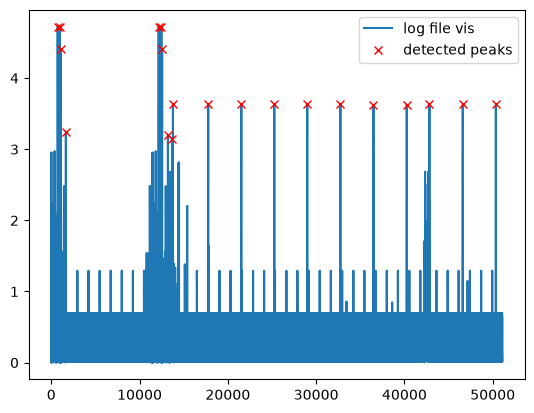

In [36]:
import matplotlib.pyplot as plt
import numpy as np


def reduce(data):
    return [np.sqrt(np.sum(r)) for r in data]

def visualize(log_file: LogFile, reduce, **kwargs):
    reduced = reduce(log_file._vectorized)
    prominent = lf.find_distinctive(fn=reduce, **kwargs)
    normalized = np.abs(reduced - np.mean(reduced))
    plt.plot(range(len(reduced)), normalized, label="log file vis")
    plt.plot(prominent, [normalized[peak] for peak in prominent], "rx", label="detected peaks")
    plt.legend()


visualize(lf, reduce, prominence=3, distance=1, height=1, context_size=1, kernel_size=1)

See? It has peaks. `find_distinctive()` lets you locate those peaks, and the keyword arguments let you tune the search, and see what pops out. Running the search with the smallest possible values for the search parameters lets you quickly weed out the noise and leave only the -- supposedly -- more interesting parts.

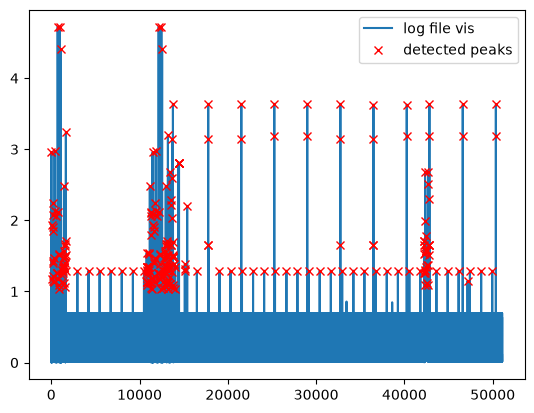

In [37]:
visualize(lf, reduce, prominence=1, distance=1, height=1, context_size=1, kernel_size=1)